In [2]:

%pip install pandas numpy matplotlib seaborn scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("city_day.csv")

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Dataset Shape: (29531, 16)
Columns: ['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [5]:

delhi = df[df["City"] == "Delhi"].copy()

delhi["Date"] = pd.to_datetime(delhi["Date"])
delhi = delhi.sort_values("Date")

print("Total Delhi records:", len(delhi))
print("Missing AQI values:", delhi["AQI"].isnull().sum())

display(delhi.head())


Total Delhi records: 2009
Missing AQI values: 10


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
10229,Delhi,2015-01-01,313.22,607.98,69.16,36.39,110.59,33.85,15.20,9.25,41.68,14.36,24.86,9.84,472.0,Severe
10230,Delhi,2015-01-02,186.18,269.55,62.09,32.87,88.14,31.83,9.54,6.65,29.97,10.55,20.09,4.29,454.0,Severe
10231,Delhi,2015-01-03,87.18,131.90,25.73,30.31,47.95,69.55,10.61,2.65,19.71,3.91,10.23,1.99,143.0,Moderate
10232,Delhi,2015-01-04,151.84,241.84,25.01,36.91,48.62,130.36,11.54,4.63,25.36,4.26,9.71,3.34,319.0,Very Poor
10233,Delhi,2015-01-05,146.60,219.13,14.01,34.92,38.25,122.88,9.20,3.33,23.20,2.80,6.21,2.96,325.0,Very Poor


In [6]:

delhi = delhi[["Date", "AQI"]].copy()

delhi = delhi.dropna(subset=["AQI"])
delhi = delhi.sort_values("Date")
delhi = delhi.reset_index(drop=True)

print("Cleaned records:", len(delhi))
print("Missing values:")
print(delhi.isnull().sum())

display(delhi.head())


Cleaned records: 1999
Missing values:
Date    0
AQI     0
dtype: int64


,Date,AQI
0,2015-01-01,472.0
1,2015-01-02,454.0
2,2015-01-03,143.0
3,2015-01-04,319.0
4,2015-01-05,325.0


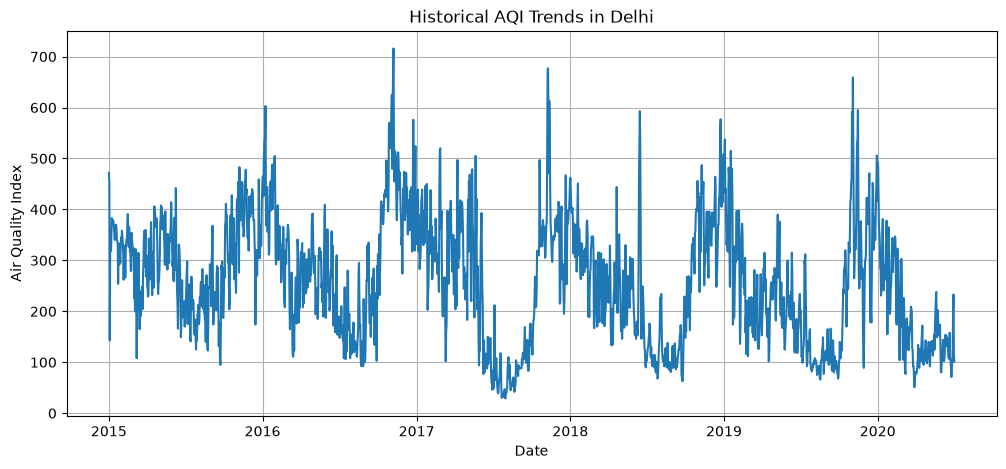

In [7]:

plt.figure(figsize=(12, 5))

plt.plot(delhi["Date"], delhi["AQI"])

plt.title("Historical AQI Trends in Delhi")
plt.xlabel("Date")
plt.ylabel("Air Quality Index")
plt.grid(True)

plt.show()


In [8]:

print("First date:", delhi["Date"].min())
print("Last date:", delhi["Date"].max())

print("Duplicate dates:", delhi["Date"].duplicated().sum())

expected_days = pd.date_range(
    start=delhi["Date"].min(),
    end=delhi["Date"].max(),
    freq="D"
)

missing_dates = expected_days.difference(delhi["Date"])

print("Missing dates:", len(missing_dates))


First date: 2015-01-01 00:00:00
Last date: 2020-07-01 00:00:00
Duplicate dates: 0
Missing dates: 10


In [9]:

delhi = delhi.set_index("Date")

delhi = delhi.asfreq("D")

delhi["AQI"] = delhi["AQI"].interpolate(method="time")

delhi = delhi.reset_index()

print("Total records:", len(delhi))
print("Missing values:", delhi["AQI"].isnull().sum())

display(delhi.head())


Total records: 2009
Missing values: 0


,Date,AQI
0,2015-01-01,472.0
1,2015-01-02,454.0
2,2015-01-03,143.0
3,2015-01-04,319.0
4,2015-01-05,325.0


In [10]:

data = df[df["City"] == "Delhi"][["Date", "AQI"]].copy()

data["Date"] = pd.to_datetime(data["Date"])
data = data.sort_values("Date").set_index("Date").asfreq("D")

data["Month"] = data.index.month
data["Day"] = data.index.day
data["DayOfWeek"] = data.index.dayofweek

data["AQI_Lag1"] = data["AQI"].shift(1)
data["AQI_Lag3"] = data["AQI"].shift(3)
data["AQI_Lag7"] = data["AQI"].shift(7)

data["AQI_Rolling3"] = data["AQI"].shift(1).rolling(3).mean()
data["AQI_Rolling7"] = data["AQI"].shift(1).rolling(7).mean()

print("Temporal features created successfully")
display(data.head(12))


Temporal features created successfully


,AQI,Month,Day,DayOfWeek,AQI_Lag1,AQI_Lag3,AQI_Lag7,AQI_Rolling3,AQI_Rolling7
Date,,,,,,,,,
2015-01-01,472.0,1,1,3,NaN,NaN,NaN,NaN,NaN
2015-01-02,454.0,1,2,4,472.0,NaN,NaN,NaN,NaN
2015-01-03,143.0,1,3,5,454.0,NaN,NaN,NaN,NaN
2015-01-04,319.0,1,4,6,143.0,472.0,NaN,356.333333,NaN
2015-01-05,325.0,1,5,0,319.0,454.0,NaN,305.333333,NaN
2015-01-06,318.0,1,6,1,325.0,143.0,NaN,262.333333,NaN
2015-01-07,353.0,1,7,2,318.0,319.0,NaN,320.666667,NaN
2015-01-08,383.0,1,8,3,353.0,325.0,472.0,332.000000,340.571429
2015-01-09,375.0,1,9,4,383.0,318.0,454.0,351.333333,327.857143


In [11]:

data["Target_1Day"] = data["AQI"].shift(-1)
data["Target_3Day"] = data["AQI"].shift(-3)
data["Target_7Day"] = data["AQI"].shift(-7)

data = data.dropna().copy()

print("Final dataset shape:", data.shape)
display(data.head())


Final dataset shape: (1944, 12)


,AQI,Month,Day,DayOfWeek,AQI_Lag1,AQI_Lag3,AQI_Lag7,AQI_Rolling3,AQI_Rolling7,Target_1Day,Target_3Day,Target_7Day
Date,,,,,,,,,,,,
2015-01-08,383.0,1,8,3,353.0,325.0,472.0,332.000000,340.571429,375.0,379.0,340.0
2015-01-09,375.0,1,9,4,383.0,318.0,454.0,351.333333,327.857143,376.0,375.0,356.0
2015-01-10,376.0,1,10,5,375.0,353.0,143.0,370.333333,316.571429,379.0,366.0,360.0
2015-01-11,379.0,1,11,6,376.0,383.0,319.0,378.000000,349.857143,375.0,353.0,370.0
2015-01-12,375.0,1,12,0,379.0,375.0,325.0,376.666667,358.428571,366.0,340.0,362.0


In [12]:

features = [
    "AQI", "Month", "Day", "DayOfWeek",
    "AQI_Lag1", "AQI_Lag3", "AQI_Lag7",
    "AQI_Rolling3", "AQI_Rolling7"
]

targets = ["Target_1Day", "Target_3Day", "Target_7Day"]

split = int(len(data) * 0.8)

train = data.iloc[:split].copy()
test = data.iloc[split:].copy()

X_train = train[features]
X_test = test[features]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training ends:", train.index.max())
print("Testing starts:", test.index.min())


Training records: 1555
Testing records: 389
Training ends: 2019-06-01 00:00:00
Testing starts: 2019-06-02 00:00:00


In [13]:

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results = []
predictions = {}

for target in targets:
    horizon = int(target.split("_")[1].replace("Day", ""))
    valid_train = train[train.index + pd.Timedelta(days=horizon) < test.index.min()]

    X_train_safe = valid_train[features]
    y_train = valid_train[target]
    y_test = test[target]

    for name, model in models.items():
        model.fit(X_train_safe, y_train)
        y_pred = model.predict(X_test)

        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        results.append({
            "Model": name,
            "Horizon": target,
            "MAE": round(mae, 2),
            "RMSE": round(rmse, 2),
            "R2": round(r2, 3)
        })

        predictions[(name, target)] = y_pred

results_df = pd.DataFrame(results)

display(results_df)


,Model,Horizon,MAE,RMSE,R2
0,Linear Regression,Target_1Day,31.80,43.54,0.856
1,Random Forest,Target_1Day,32.29,44.72,0.848
2,Gradient Boosting,Target_1Day,32.50,44.85,0.847
3,Linear Regression,Target_3Day,54.34,71.74,0.610
4,Random Forest,Target_3Day,54.27,74.66,0.578
5,Gradient Boosting,Target_3Day,54.19,73.60,0.590
6,Linear Regression,Target_7Day,62.80,80.16,0.515
7,Random Forest,Target_7Day,65.14,83.76,0.470
8,Gradient Boosting,Target_7Day,62.38,80.75,0.508


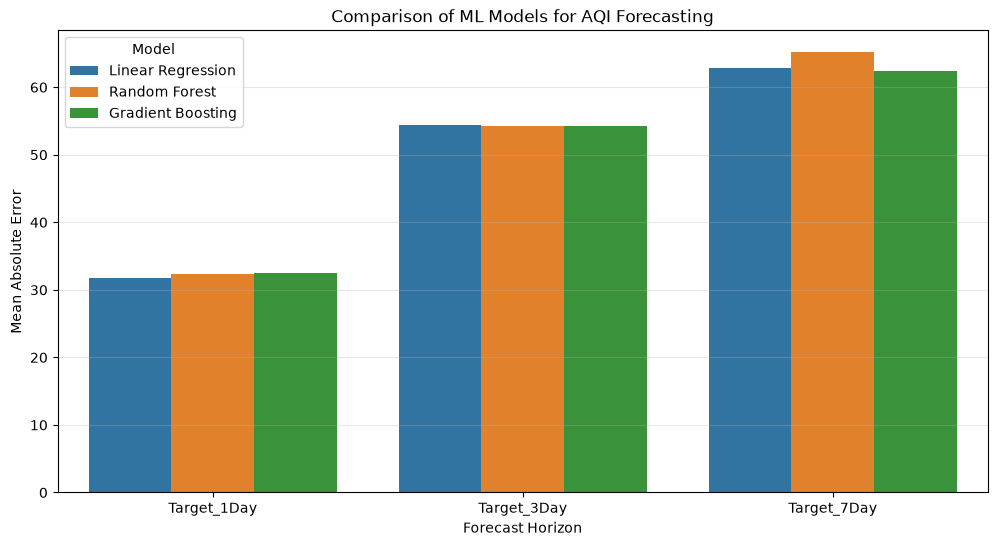

In [14]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Horizon",
    y="MAE",
    hue="Model"
)

plt.title("Comparison of ML Models for AQI Forecasting")
plt.xlabel("Forecast Horizon")
plt.ylabel("Mean Absolute Error")
plt.grid(axis="y", alpha=0.3)

plt.show()


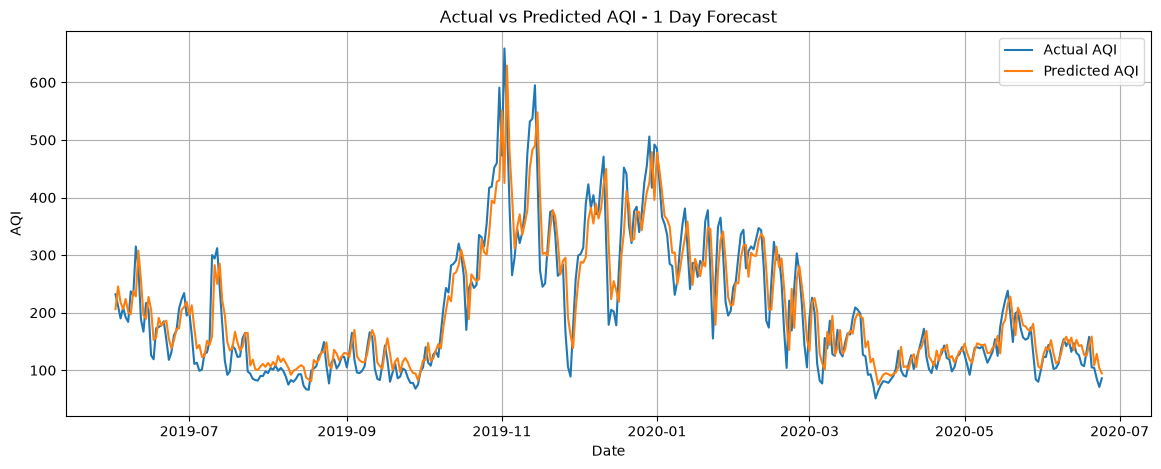

In [15]:

target = "Target_1Day"
model_name = "Linear Regression"

plt.figure(figsize=(14, 5))

plt.plot(
    test.index,
    test[target],
    label="Actual AQI"
)

plt.plot(
    test.index,
    predictions[(model_name, target)],
    label="Predicted AQI"
)

plt.title("Actual vs Predicted AQI - 1 Day Forecast")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()
plt.grid(True)

plt.show()


In [16]:

results_df.to_csv("AQI_Model_Results.csv", index=False)

print("Results saved successfully!")


Results saved successfully!


In [17]:

baseline_results = []

for target in targets:
    y_true = test[target]
    y_pred = test["AQI"]

    baseline_results.append({
        "Horizon": target,
        "MAE": round(mean_absolute_error(y_true, y_pred), 2),
        "RMSE": round(np.sqrt(mean_squared_error(y_true, y_pred)), 2),
        "R2": round(r2_score(y_true, y_pred), 3)
    })

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df)


,Horizon,MAE,RMSE,R2
0,Target_1Day,31.17,44.74,0.848
1,Target_3Day,56.45,80.70,0.507
2,Target_7Day,67.05,94.64,0.324


In [18]:

from sklearn.base import clone
import joblib

trained_models = {}

for target in targets:
    horizon = int(target.split("_")[1].replace("Day", ""))
    valid_train = train[
        train.index + pd.Timedelta(days=horizon) < test.index.min()
    ]

    for name, model in models.items():
        trained = clone(model)
        trained.fit(valid_train[features], valid_train[target])
        trained_models[(name, target)] = trained

joblib.dump({
    "models": trained_models,
    "features": features
}, "AQI_Trained_Models.pkl")

results_df.to_csv("AQI_Model_Results.csv", index=False)

print("All 9 trained models and results saved successfully!")


All 9 trained models and results saved successfully!


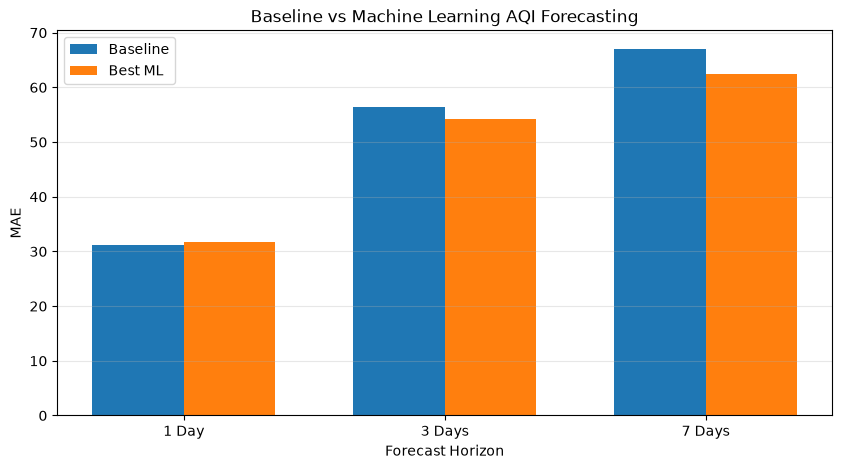

In [19]:

baseline_df.to_csv("AQI_Baseline_Results.csv", index=False)

plt.figure(figsize=(10, 5))

horizons = ["1 Day", "3 Days", "7 Days"]
baseline_mae = baseline_df["MAE"].tolist()
best_ml_mae = [
    results_df[results_df["Horizon"] == target]["MAE"].min()
    for target in targets
]

x = np.arange(3)
width = 0.35

plt.bar(x - width/2, baseline_mae, width, label="Baseline")
plt.bar(x + width/2, best_ml_mae, width, label="Best ML")

plt.xticks(x, horizons)
plt.xlabel("Forecast Horizon")
plt.ylabel("MAE")
plt.title("Baseline vs Machine Learning AQI Forecasting")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.savefig("AQI_Baseline_Comparison.png", dpi=300, bbox_inches="tight")
plt.show()


In [20]:

%pip install requests streamlit joblib



   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
    --------------------------------------- 0.3/11.2 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.2 MB 1.5 MB/s eta 0:00:08
   --- ------------------------------------ 1.0/11.2 MB 1.6 MB/s eta 0:00:07
   ---- ----------------------------------- 1.3/11.2 MB 1.6 MB/s eta 0:00:07
   ------ --------------------------------- 1.8/11.2 MB 1.8 MB/s eta 0:00:06
   -------- ------------------------------- 2.4/11.2 MB 1.9 MB/s eta 0:00:05
   ---------- ----------------------------- 2.9/11.2 MB 2.0 MB/s eta 0:00:05
   ------------ --------------------------- 3.4/11.2 MB 2.0 MB/s eta 0:00:04
   ------------- -------------------------- 3.9/11.2 MB 2.2 MB/s eta 0:00:04
   ---------------- ----------------------- 4.7/11.2 MB 2.3 MB/s eta 0:00:03
   ------------------- -------------------- 5.5/11.2 MB 2.4 MB/s eta 0:00:03
   -----------------


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:

import requests
import pandas as pd

url = "https://air-quality-api.open-meteo.com/v1/air-quality"

params = {
    "latitude": 28.6139,
    "longitude": 77.2090,
    "current": "us_aqi,pm2_5,pm10",
    "hourly": "us_aqi",
    "past_days": 14,
    "forecast_days": 1,
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

live_data = response.json()

print("Current AQI and pollution data:")
print(live_data["current"])

hourly = pd.DataFrame(live_data["hourly"])
hourly["time"] = pd.to_datetime(hourly["time"])

display(hourly.tail(10))


Current AQI and pollution data:
{'time': '2026-11-19T15:30', 'interval': 3600, 'us_aqi': 166, 'pm2_5': 47.1, 'pm10': 47.6}


,time,us_aqi
350,2026-11-19 14:00:00,166
351,2026-11-19 15:00:00,166
352,2026-11-19 16:00:00,167
353,2026-11-19 17:00:00,167
354,2026-11-19 18:00:00,167
355,2026-11-19 19:00:00,168
356,2026-11-19 20:00:00,169
357,2026-11-19 21:00:00,170
358,2026-11-19 22:00:00,172
359,2026-11-19 23:00:00,174


In [22]:

from datetime import datetime

url = "https://air-quality-api.open-meteo.com/v1/air-quality"

params = {
    "latitude": 28.6139,
    "longitude": 77.2090,
    "hourly": "us_aqi",
    "past_days": 90,
    "forecast_days": 1,
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

api_data = response.json()

daily = pd.DataFrame(api_data["hourly"])
daily["time"] = pd.to_datetime(daily["time"])
daily["Date"] = daily["time"].dt.date

daily = daily.groupby("Date", as_index=False)["us_aqi"].mean()

daily = daily.rename(columns={"us_aqi": "AQI"})

print("Total daily records:", len(daily))
display(daily.head())
display(daily.tail())


Total daily records: 91


,Date,AQI
0,2026-08-21,149.333333
1,2026-08-22,150.666667
2,2026-08-23,158.583333
3,2026-08-24,159.083333
4,2026-08-25,169.041667


,Date,AQI
86,2026-11-15,162.958333
87,2026-11-16,173.958333
88,2026-11-17,157.041667
89,2026-11-18,165.208333
90,2026-11-19,166.291667


In [23]:

from datetime import datetime, timedelta
from zoneinfo import ZoneInfo

today = datetime.now(ZoneInfo("Asia/Kolkata")).date()

end_date = today - timedelta(days=1)
start_date = end_date - timedelta(days=729)

url = "https://air-quality-api.open-meteo.com/v1/air-quality"

params = {
    "latitude": 28.6139,
    "longitude": 77.2090,
    "start_date": start_date.isoformat(),
    "end_date": end_date.isoformat(),
    "hourly": "us_aqi",
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

api_data = response.json()

hourly_data = pd.DataFrame(api_data["hourly"])
hourly_data["time"] = pd.to_datetime(hourly_data["time"])
hourly_data["Date"] = hourly_data["time"].dt.date

daily_counts = hourly_data.groupby("Date")["us_aqi"].count()
daily_means = hourly_data.groupby("Date")["us_aqi"].mean()

daily = pd.DataFrame({
    "AQI": daily_means,
    "Count": daily_counts
})

daily = daily[daily["Count"] == 24]
daily = daily[["AQI"]].dropna().reset_index()

daily["Date"] = pd.to_datetime(daily["Date"])

print("Total complete days:", len(daily))
print("First date:", daily["Date"].min())
print("Last date:", daily["Date"].max())

display(daily.head())
display(daily.tail())


Total complete days: 730
First date: 2024-11-19 00:00:00
Last date: 2026-11-18 00:00:00


,Date,AQI
0,2024-11-19,178.625000
1,2024-11-20,181.500000
2,2024-11-21,190.750000
3,2024-11-22,203.208333
4,2024-11-23,246.166667


,Date,AQI
725,2026-11-14,198.958333
726,2026-11-15,162.958333
727,2026-11-16,173.958333
728,2026-11-17,157.041667
729,2026-11-18,165.208333
